In [109]:
import pandas as pd


df = pd.DataFrame(columns=["calendarDate", "hrv"])

file_list = ["data_preprocessed/2025-06-24_2025-10-01_116118876_healthStatusData.json",
             "data_preprocessed/2025-10-02_2026-01-09_116118876_healthStatusData.json",
             "data_preprocessed/2026-01-10_2026-04-19_116118876_healthStatusData.json",
             "data_preprocessed/2026-04-20_2026-07-28_116118876_healthStatusData.json",
             "data_preprocessed/2026-07-29_2026-11-06_116118876_healthStatusData.json"
            ]

for json_file in file_list:
    df_temp = pd.read_json(json_file, orient="records")

    df_temp["hrv"] = df_temp["metrics"].apply(lambda x: x[0]["value"])
    df_temp = df_temp[["calendarDate", "hrv"]]

    df = pd.concat([df, df_temp])

#df = df.sort_values(by="calendarDate")
df = df[["calendarDate", "hrv"]]


In [110]:
# merge in the manual data from excel

df_manual = pd.read_csv("data_preprocessed/manual_data.csv")

df = pd.concat([df, df_manual])
df = df.sort_values(by="calendarDate")
df = df[["calendarDate", "hrv"]]
df = df.reset_index(drop=True)

df = df.iloc[:-5]

df.to_csv("data/elliot_hrv_data.csv")

print(df)

    calendarDate   hrv
0     2025-05-01  49.0
1     2025-05-02  53.0
2     2025-05-03  49.0
3     2025-05-04  60.0
4     2025-05-05  39.0
..           ...   ...
528   2026-10-28  47.0
529   2026-10-29  41.0
530   2026-10-30  29.0
531   2026-10-31  38.0
532   2026-11-01  39.0

[533 rows x 2 columns]


## account for missing days

In [111]:
df['calendarDate'] = pd.to_datetime(df['calendarDate']).dt.normalize()

full_dates = pd.date_range(start=df['calendarDate'].min(), end=df['calendarDate'].max(), freq='D')

df = df.set_index('calendarDate').reindex(full_dates).rename_axis('calendarDate').reset_index()


df.to_csv("data/elliot_hrv_data.csv")

print(df)

df["hrv"] = df["hrv"].astype(float).interpolate().round(0).astype(int)





    calendarDate   hrv
0     2025-05-01  49.0
1     2025-05-02  53.0
2     2025-05-03  49.0
3     2025-05-04  60.0
4     2025-05-05  39.0
..           ...   ...
545   2026-10-28  47.0
546   2026-10-29  41.0
547   2026-10-30  29.0
548   2026-10-31  38.0
549   2026-11-01  39.0

[550 rows x 2 columns]


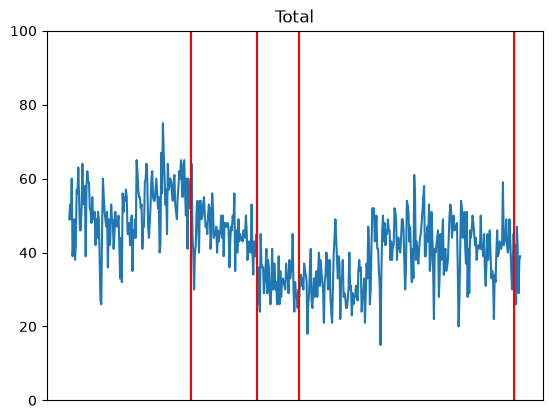

In [112]:
import matplotlib.pyplot as plt


indices = ["2025-09-26", "2025-12-15", "2026-02-05", "2026-10-25"]


plt.plot(df["calendarDate"], df["hrv"])
plt.ylim(0, 100)
plt.xticks([0, len(df)/2, len(df)-1])
#plt.xlim(0, len(df)-1)
plt.title("Total")
plt.vlines(x= indices, ymin= 0, ymax=100, colors="red")
plt.show()

### sick days column

In [150]:
# from my obsidian table
import datetime

onset_days = ["2025-06-05",
              "2025-06-30",
              "2025-09-26",
              "2025-12-15",
              "2026-02-05",
              "2026-10-25"
]

final_days = ["2025-06-13",
              "2025-07-06",
              "2025-10-08",
              "2025-12-17",
              "2026-02-15",
              "2026-10-31"
]

sick_periods = dict(zip(onset_days, final_days))
sick_days = []

for onset_date in sick_periods.keys():
    for i in range((datetime.date.fromisoformat(sick_periods[onset_date]) - datetime.date.fromisoformat(onset_date)).days + 1):
        date = (datetime.date.fromisoformat(onset_date) + datetime.timedelta(days=i))
        sick_days.append(date.isoformat())



start_date = datetime.date(2025, 5, 1)
end_date = datetime.date(2026, 11, 1)
column_isFirstSickDay = []
column_isSickDay = []

for i in range((end_date - start_date).days + 1):
    i_date = (start_date + datetime.timedelta(days=i)).isoformat()

    column_isFirstSickDay.append(int(i_date in sick_periods.keys()))
    
    column_isSickDay.append(int(i_date in sick_days))


df["isSickDay"] = column_isSickDay
df["isFirstSickDay"] = column_isFirstSickDay
df["calendarDate"] = df["calendarDate"].apply(datetime.date.isoformat)

print(df.head(38))

   calendarDate  hrv  isSickDay  isFirstSickDay
0    2025-05-01   49          0               0
1    2025-05-02   53          0               0
2    2025-05-03   49          0               0
3    2025-05-04   60          0               0
4    2025-05-05   39          0               0
5    2025-05-06   43          0               0
6    2025-05-07   49          0               0
7    2025-05-08   38          0               0
8    2025-05-09   42          0               0
9    2025-05-10   57          0               0
10   2025-05-11   56          0               0
11   2025-05-12   63          0               0
12   2025-05-13   55          0               0
13   2025-05-14   46          0               0
14   2025-05-15   46          0               0
15   2025-05-16   52          0               0
16   2025-05-17   64          0               0
17   2025-05-18   53          0               0
18   2025-05-19   57          0               0
19   2025-05-20   58          0         

In [121]:
# final csv export
df.to_csv("data/elliot_hrv_data.csv")

0      2025-05-01
1      2025-05-02
2      2025-05-03
3      2025-05-04
4      2025-05-05
          ...    
545    2026-10-28
546    2026-10-29
547    2026-10-30
548    2026-10-31
549    2026-11-01
Name: calendarDate, Length: 550, dtype: str
2025-05-01


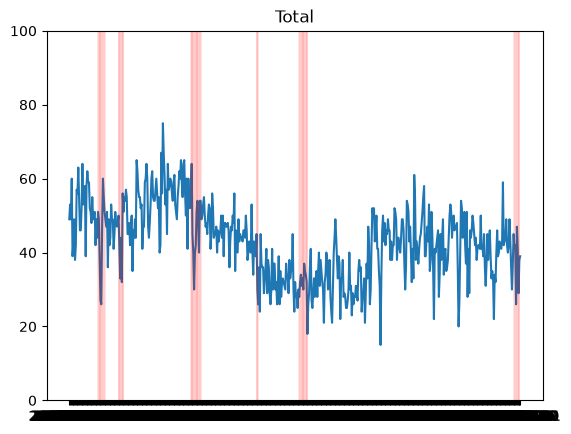

In [154]:
onlysickdays = df[df["isSickDay"] == 1]
cdates = df["calendarDate"]
print(cdates)
print(cdates[0])

plt.plot(df["calendarDate"], df["hrv"])
plt.ylim(0, 100)
plt.title("Total")

plt.vlines(x = onlysickdays["calendarDate"], ymin= 0, ymax=100, colors="red", alpha=0.1)

plt.show()
